# 07 · A smooth shadow-rate model for the zero-lower-bound years

In 2009–2022 short rates sat at or below zero in all three currencies, for
13 years in GBP. The linear DNS model has no notion of a floor. It forecasts
a short rate that drifts below the bound, and it treats a curve pinned at the
bound like any other curve. README §7.6 flagged this regime problem for EUR
and GBP (roadmap step 7b item 6).

The smooth shadow-rate DNS of Opschoor & van der Wel (2025) keeps the
Nelson–Siegel factors and their VAR, but reads each observed yield through
a smooth maximum:

y(τ) = r_LB + κ f((s(τ) − r_LB)/κ),  f(x) = xΦ(x) + φ(x),  s(τ) = Λ(τ) x_t.

- **Far above the bound** y = s, the linear model.
- **Near the bound** yields flatten towards r_LB while the shadow curve s
  can keep falling.
- **Identity behind the formula:** κ f(x/κ) = E[max(0, x + κZ)]. So κ acts
  like the volatility in a bond-option price.

**Choices, fixed before the run** (README §8, commit `a35a586`):

- κ = 1 (the paper's forecasting setting).
- r_LB = min(0, lowest yield in the estimation sample), learnt in real time.
- μ is fixed at the real-time sample mean, as for the linear model.
- Estimation is by maximum likelihood with the extended Kalman filter, from
  the linear fit of the same sample.
- Two forecasts: **plug-in** (the forecast shadow curve through the
  measurement function) and **mean** (the expectation over the shadow
  curve's forecast variance: the same formula with κ' = √(κ² + v)). Each is
  run plain and with AR(1) errors.

**One change after the grid was fixed, before any forecast was looked at.**
The first run imposed stationarity by rejecting explosive A, as the linear
code does. Diagnostics on the fits showed that this left L-BFGS-B stopping
up to 60 log-likelihood points short of the optimum: the shadow model's
level wants to sit near a unit root, and line searches kept hitting the
rejection wall. Restarts from perturbed points found the better optima. The
estimator now uses the Ansley–Kohn (1986) reparameterisation, as the paper
does (`yck.model.shadow.stationary_from_free`). Every parameter vector is
then a stationary VAR, and a single start reaches the restart optima to
within about 1 point. The first run's fits were discarded through a new
version in the cache key.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from yck.eval.backtest import dns_kalman_forecasts, dns_two_step_forecasts, random_walk_forecasts, forward_forecasts
from yck.eval.grid import (STANDARD_GRID, BACKTEST_DEFAULTS, accuracy_grid, anchor_grid, shadow_grid, plan_runs,
                           combination_forecasts, ensure_results, tag_of, _grid_for)
from yck.eval.stats import dm_table, mcs_table
from yck.model.statespace_dns import fit_dns_mle
from yck.model.shadow import fit_shadow_dns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, CONFIG, DATA = ROOT / "data/results", ROOT / "config/data_sources.yaml", ROOT / "data"
CCYS = ["USD", "EUR", "GBP"]
H = (1, 6, 12)
SHOW = {"USD": ["3m", "12m", "24m", "60m", "120m"], "EUR": ["3m", "12m", "24m", "60m", "120m"],
        "GBP": ["6m", "12m", "24m", "60m", "120m"]}
FIRST_ORIGIN = {c: BACKTEST_DEFAULTS[c][1] for c in CCYS}
ZLB = {"USD": ("2009", "2015"), "EUR": ("2014", "2022"), "GBP": ("2009", "2021")}  # policy rate at or near zero
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
CAP = [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]

for g in (STANDARD_GRID, accuracy_grid, anchor_grid, shadow_grid):  # one grid run if anything is missing
    ensure_results(CCYS, DATA, CONFIG, grid=g)

def name_of(row):
    m, lam, tau, ep, err, anc, sr = tuple(row) + (None,) * (7 - len(row))
    base = "shadow" if sr else ("policy rate" if m == ("policy_rate",) else "full macro" if m else "yields")
    base += "" if lam == "fixed" else ", λ est."
    base += f", shrink {tau:g}" if tau is not None else ""
    base += f", endpoint {ep}" if ep else ""
    base += " + AR(1)" if err == "ar1" else " + AR(1) with mean" if err == "ar1c" else ""
    return base + (", anchored" if anc else "") + (f" ({sr})" if sr else "")

y, fc = {}, {}
for c in CCYS:
    est = BACKTEST_DEFAULTS[c][0]
    full = pd.read_parquet(ROOT / f"data/processed/curves_{c}.parquet")
    y[c] = full.loc[est:] if est else full
    fc[c] = {}
    for g in (STANDARD_GRID, accuracy_grid, anchor_grid, shadow_grid):
        for r in _grid_for(g, c):
            fc[c][name_of(r)] = {h: pd.read_parquet(RESULTS / f"fc_{c}_kalman_{tag_of(r)}_h{h}.parquet") for h in H}
    fc[c]["two-step AR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["two-step VAR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c], kind="var1")
    fc[c]["random walk"] = random_walk_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["forwards"] = forward_forecasts(pd.read_parquet(ROOT / f"data/processed/curves_ext_{c}.parquet"),
                                          y[c].columns, H, FIRST_ORIGIN[c])
    fc[c].update(combination_forecasts(c, DATA, CONFIG))
SHADOW = [name_of(r) for r in _grid_for(shadow_grid, "USD")]
LINEAR_OF = {s: ("yields + AR(1)" if "AR(1)" in s else "yields") for s in SHADOW}
pd.DataFrame({c: {"models compared": len(fc[c])} for c in CCYS})

,USD,EUR,GBP
models compared,48,42,36


## 1. The fits

Each refit's lower bound and log-likelihood gain over the linear model on
the same sample. The gain is close to zero while the sample holds only
"normal" rates, and grows once the zero-rate years enter it. EUR's first
refit (2010) is the one case where the shadow model fits worse: κ and r_LB
are fixed, so it does not nest the linear model exactly.

,USD,EUR,GBP
refits,27,17,17
r_LB first / last,0.00 / 0.00,0.00 / -0.95,0.00 / -0.16
"log-lik gain, first refit",-0.0,-31.2,62.0
"log-lik gain, last refit",1058.3,535.2,823.6
optimiser stopped on tolerance,4,0,1


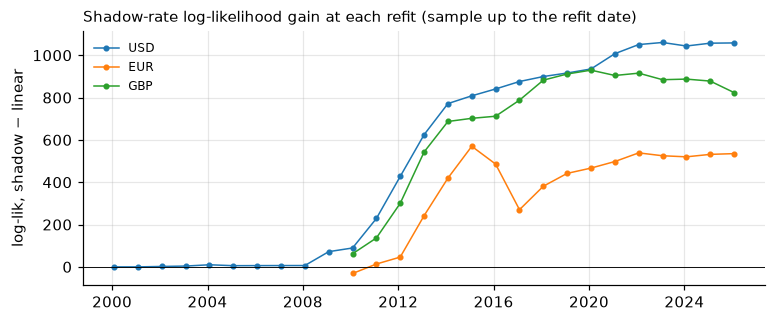

In [2]:
rows, gains = {}, {}
for c in CCYS:
    run = [kw for cc, tag, kw in plan_runs([c], DATA, CONFIG, grid=shadow_grid) if tag == "lamfixed_sr-plugin"][0]
    fits = []
    dns_kalman_forecasts(**run, horizons=(1,), cache_dir=RESULTS / "cache", fits=fits)
    g = pd.Series({t: f.loglik - f.linear_loglik for t, f in fits})
    gains[c] = g
    rows[c] = {"refits": len(fits), "r_LB first / last": f"{fits[0][1].lb:.2f} / {fits[-1][1].lb:.2f}",
               "log-lik gain, first refit": round(g.iloc[0], 1), "log-lik gain, last refit": round(g.iloc[-1], 1),
               "optimiser stopped on tolerance": int(sum(not f.converged for _, f in fits))}
display(pd.DataFrame(rows))
fig, ax = plt.subplots(figsize=(8, 3))
for c in CCYS:
    ax.plot(gains[c], marker="o", ms=3, lw=1, label=c)
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("log-lik, shadow − linear"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Shadow-rate log-likelihood gain at each refit (sample up to the refit date)", loc="left", fontsize=10);

## 2. The shadow short rate

The full-sample fits' filtered shadow short rate s(0) = level + slope,
against the observed short end. While the curve sits at the bound, the
shadow rate keeps moving and measures how far below zero policy is, in the
model's terms.

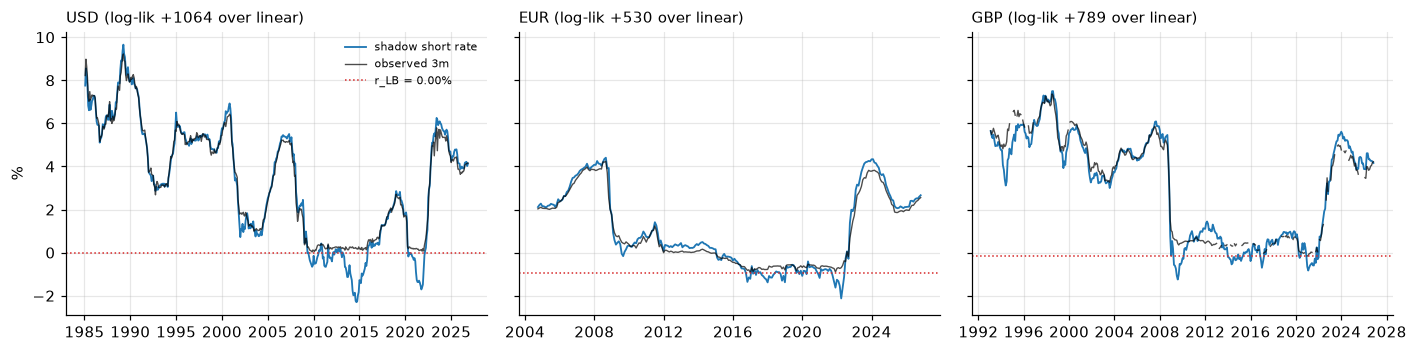

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, c in zip(axes, CCYS):
    lin = fit_dns_mle(y[c], n_starts=6)
    sh = fit_shadow_dns(y[c], lin.params, lin.loglik)
    a = sh.filtered_states(y[c])
    ax.plot(y[c].index, a[:, 0] + a[:, 1], lw=1.2, label="shadow short rate")
    ax.plot(y[c][SHOW[c][0]], lw=0.9, color="k", alpha=0.7, label=f"observed {SHOW[c][0]}")
    ax.axhline(sh.lb, ls=":", color="C3", lw=1, label=f"r_LB = {sh.lb:.2f}%")
    ax.set_title(f"{c} (log-lik +{sh.loglik - lin.loglik:.0f} over linear)", loc="left", fontsize=10)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=7, frameon=False); fig.tight_layout()

## 3. Shadow against linear

RMSE ratio of each shadow variant to the linear model with the same error
model (Diebold–Mariano, two-sided stars; < 1 means the shadow model wins).

In [4]:
def after(c, h):
    return y[c].loc[pd.Timestamp(FIRST_ORIGIN[c]) + pd.offsets.MonthEnd(h):]

def vs(c, bench, h, names, field="cell"):
    t = dm_table({n: fc[c][n][h] for n in [bench] + names}, bench, after(c, h), h, SHOW[c])
    return t.xs(field, axis=1, level=1).T

for c in CCYS:
    t = pd.concat({f"h = {h}": pd.DataFrame({s: vs(c, LINEAR_OF[s], h, [s]).loc[s] for s in SHADOW}).T for h in H},
                  axis=1)
    display(t.style.set_caption(f"{c}: shadow ÷ linear").set_table_styles(CAP))

## 4. Against forwards and the random walk

The shadow variants and the shadow combination (set A with the shadow model
in place of the linear one), next to the linear model and combination A
from notebook 06.

In [5]:
SHOWN = ["yields", "yields + AR(1)"] + SHADOW + ["combination A, inverse MSE", "combination A-shadow, equal",
                                                 "combination A-shadow, inverse MSE"]
for c in CCYS:
    t = pd.concat({**{f"÷ forwards, h = {h}": vs(c, "forwards", h, SHOWN) for h in H},
                   **{f"÷ RW, h = {h}": vs(c, "random walk", h, SHOWN, "ratio").astype(float).round(2) for h in H}},
                  axis=1)
    display(t.style.set_caption(f"{c}").set_table_styles(CAP))

## 5. Bias in the zero-rate years

Mean 12-month-ahead forecast error (forecast − realised, bp) for targets in
the years the policy rate sat at or near the bound.

In [6]:
bias = {}
for c in CCYS:
    z0, z1 = ZLB[c]
    for n in ["yields", "shadow (plugin)", "shadow (mean)", "random walk", "forwards"]:
        bias[(c, f"{z0}–{z1}", n)] = {("short end (3m; GBP 6m)" if m == SHOW[c][0] else m):
                                       100 * (fc[c][n][12][m] - y[c][m]).loc[z0:z1].mean() for m in SHOW[c]}
pd.DataFrame(bias).T.round(0)

short end (3m; GBP 6m)   12m   24m   60m  120m
USD 2009–2015 yields                             34.0  34.0  41.0  50.0  21.0
              shadow (plugin)                    30.0  37.0  41.0  47.0  24.0
              shadow (mean)                      46.0  54.0  58.0  54.0  26.0
              random walk                        21.0  19.0  16.0  18.0  26.0
              forwards                           45.0  66.0  78.0  81.0  70.0
EUR 2014–2022 yields                             79.0  56.0  53.0  65.0  54.0
              shadow (plugin)                    50.0  38.0  38.0  45.0  38.0
              shadow (mean)                      56.0  44.0  43.0  49.0  42.0
              random walk                        -1.0  -6.0  -7.0  -3.0   7.0
              forwards                           -1.0  -0.0   5.0  20.0  27.0
GBP 2009–2021 yields                             14.0  18.0  32.0  59.0  53.0
              shadow (plugin)                     6.0  11.0  24.0  50.0  49.0
              shadow (mean)                      16.0  21.0  34.0  56.0  53.0
              random walk                         7.0   5.0   7.0  17.0  26.0
              forwards                           25.0  27.0  41.0  53.0  53.0

## 6. Model confidence set over everything

The 90% MCS over every model in notebooks 02–07 (squared-error loss pooled
over the maturities shown), with the p-values of the shadow models next to
the linear ones and the benchmarks.

In [7]:
SHORT = "3m / 6m (GBP)"
mcs = {(c, h): mcs_table({n: f[h] for n, f in fc[c].items()}, after(c, h), h, SHOW[c], n_boot=2000)
               .rename(columns={SHOW[c][0]: SHORT})
       for c in CCYS for h in H}
summary = {(c, f"h = {h}"): {col: f"{int((t[col] >= 0.10).sum())} / {int(t[col].notna().sum())}" for col in t.columns}
           for (c, h), t in mcs.items()}
display(pd.DataFrame(summary).T.style.set_caption("Models in the 90% MCS / models compared").set_table_styles(CAP))
KEY = ["yields", "yields + AR(1)"] + SHADOW + ["combination A, inverse MSE", "combination A-shadow, inverse MSE",
                                               "random walk", "forwards"]
pd.DataFrame({(c, f"h = {h}"): mcs[(c, h)].loc[KEY, "all"] for c in CCYS for h in H}).round(2)

USD                EUR                GBP  \
                                  h = 1 h = 6 h = 12 h = 1 h = 6 h = 12 h = 1   
model                                                                           
yields                             0.00  0.93   0.99  0.00  0.42   0.58  0.00   
yields + AR(1)                     0.69  0.94   0.99  0.09  0.35   0.57  0.72   
shadow (plugin)                    0.01  0.92   0.88  0.12  0.48   0.58  0.40   
shadow + AR(1) (plugin)            0.87  0.92   0.88  0.12  0.48   0.58  0.80   
shadow (mean)                      0.01  0.92   0.94  0.12  0.48   0.58  0.37   
shadow + AR(1) (mean)              0.87  0.92   0.94  0.12  0.48   0.58  1.00   
combination A, inverse MSE         1.00  0.95   0.99  0.87  0.96   0.86  0.72   
combination A-shadow, inverse MSE  1.00  0.95   0.99  0.87  0.96   0.87  0.72   
random walk                        0.52  0.95   0.99  0.87  0.96   0.95  0.80   
forwards                           1.00  0.95   0.99  1.00  1.00   1.00   NaN   

                                                
                                  h = 6 h = 12  
model                                           
yields                             0.69   0.82  
yields + AR(1)                     0.69   0.82  
shadow (plugin)                    0.98   0.95  
shadow + AR(1) (plugin)            0.97   0.92  
shadow (mean)                      0.98   0.97  
shadow + AR(1) (mean)              0.98   0.97  
combination A, inverse MSE         0.97   0.97  
combination A-shadow, inverse MSE  0.98   0.97  
random walk                        0.98   0.99  
forwards                           0.90   0.82

## 7. Takeaways

1. **In sample, the shadow model fits much better once the zero-rate
   years are in the data.** By 2026 the log-likelihood gain over the linear
   model is +1,058 (USD), +535 (EUR) and +824 (GBP). Before the bound was
   reached the gain is about zero. EUR's 2010 refit is −31: with κ and r_LB
   fixed, the model does not nest the linear one.
2. **EUR, where the bound mattered most, gains most at the short end:**

   | Horizon | 3m RMSE ÷ linear | Significance |
   |---|---|---|
   | h = 1 | 0.67–0.74 | 1% |
   | h = 6 | 0.78–0.82 | 5% |
   | h = 12 | 0.91–0.93 | not significant |

   - **Bias in 2014–22 drops by about a third:** 12-month-ahead 3m from +79
     to +50 bp, 10y from +54 to +38 bp (plug-in).
   - **It is still far from the benchmarks.** The random walk and forwards
     are within −7 to +27 bp. Against forwards, the EUR short end at h = 12
     is still 1.31–1.33. What remains is mean reversion: the shadow rate
     also reverts to the sample mean.
3. **GBP gains a little:**
   - h = 1: −5% at 6m and −6% at 10y;
   - h = 6: −7% at 10y (5%);
   - h = 12: −3 to −4% at 5–10y (not significant).

   In the confidence set at h = 1, the plain shadow model stays in
   (p = 0.37–0.40) where the plain linear model is out (0.00). Shadow +
   AR(1) with the exact mean has p = 1.00, the best GBP model at one month.
4. **USD hardly changes.**
   - h = 1: −3 to −6% at 3m; −3 to −4% at 10y without AR(1) errors.
   - h = 6–12: up to 2% worse (not significant).
   - Bias in 2009–15 barely moves (3m: +34 → +30 bp).
   - **Literature not reproduced:** Opschoor & van der Wel's US gains at
     12 months (about −9% at 3m in their Table 4) do not appear here. Their
     setup differs: H.15 yields from 1981, μ estimated, a fixed 0% bound,
     and monthly re-estimation.
5. **Plug-in against exact mean.** The exact mean is higher (the
   measurement is convex), so it is slightly more biased upward in the zero
   years (USD 3m: +46 against +30 bp). RMSE differs by at most 0.02.
6. **Combination.** Putting the shadow model in combination A changes
   nothing: ratios move by ±0.01, and the confidence-set p-values are the
   same.
7. **What carries forward to step 8.**
   - **EUR and GBP:** the shadow model + AR(1) (plug-in) replaces the linear
     model as the pure-model signal.
   - **USD:** the linear model stays.
   - **Combination A** is unchanged.